# **2. Mapa Semântico dos Motivos de Cartão**

Responsabilidade deste notebook:

- carregar `data/processed/card_reasons_long.csv`;
- transformar os motivos limpos em embeddings com modelo PT-BR;
- opcionalmente fazer fine-tuning com pares extraídos das próprias súmulas;
- clusterizar com HDBSCAN (ou KMeans) sobre redução UMAP intermediária;
- projetar o mapa semântico em 2D;
- gerar tabelas de interpretação por cluster, ano, time e árbitro.

## **1. Configuração**

In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan
import umap
from sentence_transformers import SentenceTransformer
from sentence_transformers import models as st_models
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 180)
plt.style.use("seaborn-v0_8-whitegrid")

In [14]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data"
PROCESSED_PATH = DATA_PATH / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROCESSED_PATH / "semantic_card_reasons"

CARD_REASONS_LONG_PATH = PROCESSED_PATH / "card_reasons_long.csv"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

# --- Modelo de embedding ---
# Troque MODEL_NAME para experimentar:
#   "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"  (padrão — mais preciso que MiniLM)
#   "neuralmind/bert-base-portuguese-cased"                        (BERTimbau — específico para PT-BR)
#   "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"  (original — mais rápido)
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"

# --- Fine-tuning com dados do domínio ---
# True: gera pares positivos das súmulas e treina com MultipleNegativesRankingLoss.
# Na segunda execução carrega o modelo salvo sem re-treinar.
FINETUNE_MODEL = True
FINETUNED_MODEL_DIR = MODELS_DIR / "football_pt_embeddings"

# Colunas de texto
TEXT_COLUMN = "reason_detail_key"        # chave de deduplicação/merge (sem acentos)
EMBEDDING_TEXT_COLUMN = "reason_detail"  # texto para embedding (com acentos — melhor para modelos PT)

## **2. Carregamento da Base Limpa**

A entrada é `card_reasons_long.csv` gerada no notebook 1.
A coluna `reason_detail` (com acentos) é usada para embedding; `reason_detail_key` (normalizada) é a chave de deduplicação.

In [15]:
REQUIRED_COLUMNS = {
    "year", "match_date", "home_team", "away_team", "arbitro",
    "card_type", "team", "reason", "reason_key",
    "reason_category", "reason_category_key",
    "reason_detail", "reason_detail_key",
}

reasons = pd.read_csv(CARD_REASONS_LONG_PATH)
missing = REQUIRED_COLUMNS.difference(reasons.columns)
if missing:
    raise ValueError(f"Colunas ausentes em card_reasons_long.csv: {sorted(missing)}")

reasons[TEXT_COLUMN] = reasons[TEXT_COLUMN].fillna("").astype(str).str.strip()
reasons = reasons[reasons[TEXT_COLUMN].ne("")].reset_index(drop=True)
reasons.head()

,year,round,game_id,game_number,match_date,home_team,away_team,arbitro,card_type,team,minute,half,reason,reason_key,reason_category,reason_category_key,reason_detail,reason_detail_key
0,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,18,1T,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Por reclamar ostensivamente com palavras e gestos.,reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisao da arbitragem. - por reclamar ostensivamente com palavras e gestos.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisao da arbitragem.,Por reclamar ostensivamente com palavras e gestos.,por reclamar ostensivamente com palavras e gestos.
1,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,37,1T,Cometer uma falta tática para impedir um ataque promissor - Calçar o adversário disputando a bola e impedir um ataque promissor .,cometer uma falta tatica para impedir um ataque promissor - calcar o adversario disputando a bola e impedir um ataque promissor .,Cometer uma falta tática para impedir um ataque promissor,cometer uma falta tatica para impedir um ataque promissor,Calçar o adversário disputando a bola e impedir um ataque promissor .,calcar o adversario disputando a bola e impedir um ataque promissor .
2,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Flamengo,18,2T,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Dar um calço em seu adversário na disputa pela bola de maneira temerária.,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola - dar um calco em seu adversario na disputa pela bola de maneira temeraria.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Dar um calço em seu adversário na disputa pela bola de maneira temerária.,dar um calco em seu adversario na disputa pela bola de maneira temeraria.
3,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,28,2T,"Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser) - Por cometer uma atitude antidesportiva fora da disputa pela bola.","outro motivo (somente neste caso, abriria um campo livre para o arbitro digitar o que quiser) - por cometer uma atitude antidesportiva fora da disputa pela bola.","Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser)","outro motivo (somente neste caso, abriria um campo livre para o arbitro digitar o que quiser)",Por cometer uma atitude antidesportiva fora da disputa pela bola.,por cometer uma atitude antidesportiva fora da disputa pela bola.
4,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Flamengo,28,2T,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Dar um calço em seu adversário na disputa pela bola de forma temerária.,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola - dar um calco em seu adversario na disputa pela bola de forma temeraria.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Dar um calço em seu adversário na disputa pela bola de forma temerária.,dar um calco em seu adversario na disputa pela bola de forma temeraria.


## **3. Preparação dos Textos para Embedding**

Os embeddings são calculados sobre textos únicos de `reason_detail_key` (chave de deduplicação),
mas o texto real enviado ao modelo é `reason_detail` (com acentos), que produz representações
melhores com modelos treinados em português.
Quando `reason_detail` está vazio, faz fallback para `reason_category`.

In [16]:
reason_counts = reasons.groupby(TEXT_COLUMN).agg(
    reason=("reason", "first"),
    reason_category=("reason_category", "first"),
    reason_category_key=("reason_category_key", "first"),
    reason_detail=("reason_detail", "first"),
    n_events=("reason", "size"),
    n_yellow=("card_type", lambda values: (values == "yellow").sum()),
    n_red=("card_type", lambda values: (values == "red").sum()),
).reset_index().rename(columns={TEXT_COLUMN: "embedding_key"})

# Usa reason_detail (com acentos) para embedding; fallback para reason_category se vazio
reason_counts["text_for_embedding"] = (
    reason_counts[EMBEDDING_TEXT_COLUMN]
    .fillna("")
    .str.strip()
    .where(lambda s: s != "", other=reason_counts["reason_category"])
)

reason_counts = reason_counts.sort_values("n_events", ascending=False).reset_index(drop=True)
reason_counts.head(15)

,embedding_key,reason,reason_category,reason_category_key,reason_detail,n_events,n_yellow,n_red,text_for_embedding
0,por calcar seu adversario de maneira temeraria na disputa de bola.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Por calçar seu adversário de maneira temerária na disputa de bola.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Por calçar seu adversário de maneira temerária na disputa de bola.,238,238,0,Por calçar seu adversário de maneira temerária na disputa de bola.
1,por cometer uma falta tatica impedindo um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor - Por cometer uma falta tática impedindo um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor,cometer uma falta tatica para impedir um ataque promissor,Por cometer uma falta tática impedindo um ataque promissor.,154,154,0,Por cometer uma falta tática impedindo um ataque promissor.
2,cometer uma falta tatica para impedir um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor - Cometer uma falta tática para impedir um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor,cometer uma falta tatica para impedir um ataque promissor,Cometer uma falta tática para impedir um ataque promissor.,125,124,1,Cometer uma falta tática para impedir um ataque promissor.
3,por retardar o reinicio de jogo.,Retardar o reinício do jogo - Por retardar o reinício de jogo.,Retardar o reinício do jogo,retardar o reinicio do jogo,Por retardar o reinício de jogo.,122,122,0,Por retardar o reinício de jogo.
4,por cometer uma falta tatica para impedir um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor - Por cometer uma falta tática para impedir um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor,cometer uma falta tatica para impedir um ataque promissor,Por cometer uma falta tática para impedir um ataque promissor.,115,115,0,Por cometer uma falta tática para impedir um ataque promissor.
5,dar uma entrada contra um adversario de maneira temeraria na disputa da bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola - Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola,dar uma entrada contra um adversario de maneira temeraria na disputa da bola,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,104,103,1,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.
6,por dar uma entrada contra seu adversario de maneira temeraria na disputa da bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola - Por dar uma entrada contra seu adversário de maneira temerária na disputa da bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola,dar uma entrada contra um adversario de maneira temeraria na disputa da bola,Por dar uma entrada contra seu adversário de maneira temerária na disputa da bola.,103,103,0,Por dar uma entrada contra seu adversário de maneira temerária na disputa da bola.
7,por calcar seu adversario de forma temeraria na disputa de bola.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Por calçar seu adversário de forma temerária na disputa de bola.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Por calçar seu adversário de forma temerária na disputa de bola.,91,91,0,Por calçar seu adversário de forma temerária na disputa de bola.
8,dar uma entrada contra um adversario de maneira temeraria na disputa de b

## **4. Modelo de Embedding**

Suporta qualquer modelo `sentence-transformers` nativo ou BERT puro (ex: `neuralmind/bert-base-portuguese-cased`)
via wrapper de mean pooling.

In [17]:
def load_embedding_model(model_name_or_path) -> SentenceTransformer:
    """Carrega modelo sentence-transformers ou BERT puro com mean pooling."""
    path = str(model_name_or_path)
    try:
        model = SentenceTransformer(path)
        print(f"[OK] Carregado via SentenceTransformer: {path}")
        return model
    except Exception:
        # Fallback: BERT puro + mean pooling (ex: neuralmind/bert-base-portuguese-cased)
        word_model = st_models.Transformer(path, max_seq_length=256)
        pooling = st_models.Pooling(
            word_model.get_word_embedding_dimension(),
            pooling_mode_mean_tokens=True,
        )
        model = SentenceTransformer(modules=[word_model, pooling])
        print(f"[OK] Carregado como BERT + mean pooling: {path}")
        return model


embedding_model = load_embedding_model(MODEL_NAME)
print(f"Dimensão dos embeddings: {embedding_model.get_sentence_embedding_dimension()}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7101.79it/s]


[OK] Carregado via SentenceTransformer: sentence-transformers/paraphrase-multilingual-mpnet-base-v2
Dimensão dos embeddings: 768


/var/folders/x8/hw9x5p0d1v9bjf56_4xc8qrh0000gn/T/ipykernel_76842/1020975091.py:21: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Dimensão dos embeddings: {embedding_model.get_sentence_embedding_dimension()}")


In [18]:
texts = reason_counts["text_for_embedding"].tolist()

embeddings = embedding_model.encode(
    texts,
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
embeddings = np.asarray(embeddings)
print(f"Embeddings computados. Shape: {embeddings.shape}")

Batches: 100%|██████████| 73/73 [00:06<00:00, 10.50it/s]

Embeddings computados. Shape: (4657, 768)


## **5. Fine-Tuning com Dados do Domínio**

Gera pares positivos diretamente das súmulas:
- `(reason_category, reason_detail)` de um mesmo cartão — sempre semanticamente próximos;
- `(detail_i, detail_j)` dentro da mesma `reason_category_key` — variações textuais da mesma infração.

Treina com `MultipleNegativesRankingLoss`: cada frase do batch serve como negativo das outras.
Na segunda execução carrega o modelo salvo sem re-treinar.

Se `FINETUNE_MODEL = False`, esta célula é ignorada.

In [19]:
if FINETUNE_MODEL:
    # modules.json é criado apenas ao final de um ft_model.save() completo
    _model_ready = (FINETUNED_MODEL_DIR / "modules.json").exists()

    if _model_ready:
        print(f"Modelo fine-tunado encontrado em {FINETUNED_MODEL_DIR}. Carregando...")
        embedding_model = load_embedding_model(FINETUNED_MODEL_DIR)
    else:
        # Remove diretório incompleto de runs anteriores que falharam
        import shutil
        if FINETUNED_MODEL_DIR.exists():
            shutil.rmtree(FINETUNED_MODEL_DIR)

        # Instala datasets (HuggingFace) se não estiver disponível
        try:
            import datasets as hf_datasets
        except ImportError:
            import subprocess, sys
            print("Instalando datasets...")
            subprocess.check_call([sys.executable, "-m", "pip", "install", "datasets", "-q"])
            import datasets as hf_datasets

        from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments
        from sentence_transformers.losses import MultipleNegativesRankingLoss
        from sentence_transformers.training_args import BatchSamplers

        # Workaround: bug no sentence-transformers 5.5.0 — IterableDataset não importado em base/trainer.py
        import sentence_transformers.base.trainer as _st_base_trainer
        if not hasattr(_st_base_trainer, "IterableDataset"):
            from torch.utils.data import IterableDataset as _IterableDataset
            _st_base_trainer.IterableDataset = _IterableDataset

        # Geração de pares positivos
        positive_pairs = []
        for cat_key, group in reasons.groupby("reason_category_key"):
            details = (
                group["reason_detail"]
                .dropna()
                .str.strip()
                .pipe(lambda s: s[s != ""])
                .unique()
                .tolist()
            )
            categories = group["reason_category"].dropna().unique().tolist()

            # (categoria padronizada, descrição livre do árbitro)
            for cat in categories[:1]:
                for det in details[:12]:
                    positive_pairs.append({"anchor": cat, "positive": det})

            # (descrição_i, descrição_j) — mesma infração, texto diferente
            sample = details[:12]
            for i in range(len(sample)):
                for j in range(i + 1, len(sample)):
                    positive_pairs.append({"anchor": sample[i], "positive": sample[j]})

        print(f"Pares positivos gerados: {len(positive_pairs):,}")
        train_dataset = hf_datasets.Dataset.from_list(positive_pairs)

        # Treino — forçado em CPU para evitar OOM no MPS (Apple Silicon)
        # Com ~2600 pares e 3 épocas, leva ~5-10 min na CPU
        ft_model = load_embedding_model(MODEL_NAME)
        train_loss = MultipleNegativesRankingLoss(ft_model)

        training_args = SentenceTransformerTrainingArguments(
            output_dir=str(FINETUNED_MODEL_DIR / "checkpoints"),
            num_train_epochs=3,
            per_device_train_batch_size=32,
            learning_rate=2e-5,
            warmup_steps=0.1,
            fp16=False,
            use_cpu=True,           # evita OOM no MPS; CPU é suficiente para este dataset
            batch_sampler=BatchSamplers.NO_DUPLICATES,
            save_strategy="no",
            logging_steps=50,
        )

        trainer = SentenceTransformerTrainer(
            model=ft_model,
            args=training_args,
            train_dataset=train_dataset,
            loss=train_loss,
        )
        trainer.train()

        ft_model.save(str(FINETUNED_MODEL_DIR))
        print(f"Modelo salvo em: {FINETUNED_MODEL_DIR}")
        embedding_model = ft_model

    # Re-encoda com o modelo fine-tunado
    embeddings = embedding_model.encode(
        texts,
        show_progress_bar=True,
        normalize_embeddings=True,
        batch_size=64,
    )
    embeddings = np.asarray(embeddings)
    print(f"Embeddings re-computados com modelo fine-tunado. Shape: {embeddings.shape}")
else:
    print("Fine-tuning desabilitado (FINETUNE_MODEL=False). Usando embeddings do modelo base.")

Modelo fine-tunado encontrado em /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_pt_embeddings. Carregando...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7575.48it/s]


[OK] Carregado via SentenceTransformer: /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_pt_embeddings


Batches: 100%|██████████| 73/73 [00:06<00:00, 10.79it/s]

Embeddings re-computados com modelo fine-tunado. Shape: (4657, 768)


## **6. Clusterização**

KMeans com silhouette score. O número de clusters é determinado automaticamente: o range `[3, √n_unique]` é derivado do tamanho do corpus, e o silhouette escolhe o melhor k dentro desse intervalo — sem parâmetros manuais. Davies-Bouldin é reportado como métrica de validação complementar.

Textos únicos: 4657 → buscando k em [3, 20]


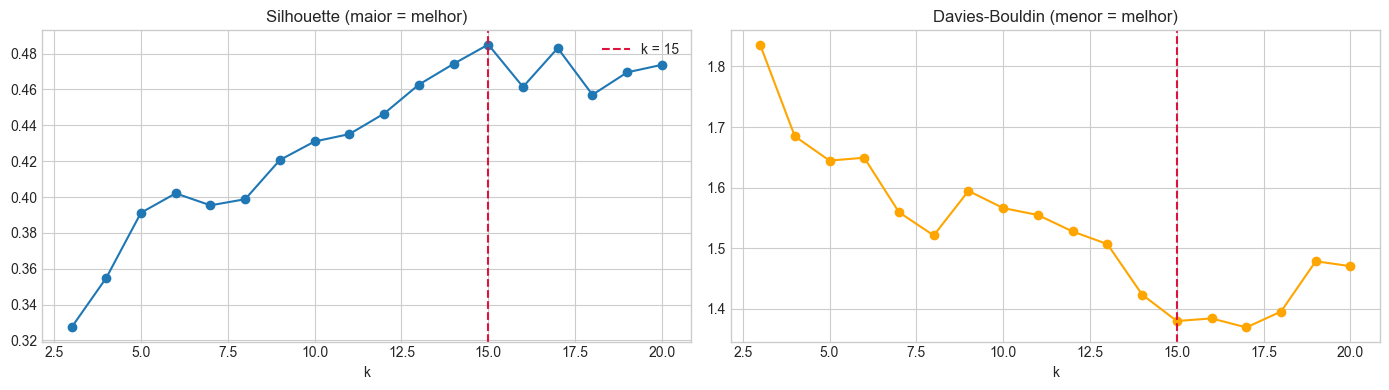

k escolhido automaticamente: 15
Avaliação: Silhouette = 0.4850 | Davies-Bouldin = 1.3801
(Silhouette: maior melhor | Davies-Bouldin: menor melhor)


In [20]:
# Range de k derivado automaticamente do corpus:
#   mínimo = 3 (abaixo disso não há granularidade semântica útil)
#   máximo = raiz quadrada do número de textos únicos, limitado a 20
#   silhouette escolhe o melhor k dentro desse intervalo — sem parâmetros manuais
n_unique = len(reason_counts)
k_min = 3
k_max = min(20, max(k_min + 1, int(np.sqrt(n_unique))))
candidate_ks = list(range(k_min, k_max + 1))

print(f"Textos únicos: {n_unique} → buscando k em [{k_min}, {k_max}]")

scores = []
for k in candidate_ks:
    labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20).fit_predict(embeddings)
    scores.append({
        "k": k,
        "silhouette": silhouette_score(embeddings, labels, metric="cosine"),
        "davies_bouldin": davies_bouldin_score(embeddings, labels),
    })

cluster_scores = pd.DataFrame(scores)
BEST_K = int(cluster_scores.sort_values("silhouette", ascending=False).iloc[0]["k"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(cluster_scores["k"], cluster_scores["silhouette"], marker="o")
axes[0].axvline(BEST_K, color="crimson", linestyle="--", label=f"k = {BEST_K}")
axes[0].set_title("Silhouette (maior = melhor)")
axes[0].set_xlabel("k")
axes[0].legend()
axes[1].plot(cluster_scores["k"], cluster_scores["davies_bouldin"], marker="o", color="orange")
axes[1].axvline(BEST_K, color="crimson", linestyle="--")
axes[1].set_title("Davies-Bouldin (menor = melhor)")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()
print(f"k escolhido automaticamente: {BEST_K}")

cluster_model = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=50)
reason_counts["cluster"] = cluster_model.fit_predict(embeddings)

sil = silhouette_score(embeddings, reason_counts["cluster"].values, metric="cosine")
db = davies_bouldin_score(embeddings, reason_counts["cluster"].values)
print(f"Avaliação: Silhouette = {sil:.4f} | Davies-Bouldin = {db:.4f}")
print("(Silhouette: maior melhor | Davies-Bouldin: menor melhor)")

In [21]:
reasons_clustered = reasons.merge(
    reason_counts[["embedding_key", "cluster"]],
    left_on=TEXT_COLUMN,
    right_on="embedding_key",
    how="left",
).drop(columns=["embedding_key"])

print(f"Cartões sem cluster: {reasons_clustered['cluster'].isna().sum()}")
reasons_clustered.head()

Cartões sem cluster: 0


,year,round,game_id,game_number,match_date,home_team,away_team,arbitro,card_type,team,minute,half,reason,reason_key,reason_category,reason_category_key,reason_detail,reason_detail_key,cluster
0,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,18,1T,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Por reclamar ostensivamente com palavras e gestos.,reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisao da arbitragem. - por reclamar ostensivamente com palavras e gestos.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisao da arbitragem.,Por reclamar ostensivamente com palavras e gestos.,por reclamar ostensivamente com palavras e gestos.,5
1,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,37,1T,Cometer uma falta tática para impedir um ataque promissor - Calçar o adversário disputando a bola e impedir um ataque promissor .,cometer uma falta tatica para impedir um ataque promissor - calcar o adversario disputando a bola e impedir um ataque promissor .,Cometer uma falta tática para impedir um ataque promissor,cometer uma falta tatica para impedir um ataque promissor,Calçar o adversário disputando a bola e impedir um ataque promissor .,calcar o adversario disputando a bola e impedir um ataque promissor .,6
2,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Flamengo,18,2T,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Dar um calço em seu adversário na disputa pela bola de maneira temerária.,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola - dar um calco em seu adversario na disputa pela bola de maneira temeraria.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Dar um calço em seu adversário na disputa pela bola de maneira temerária.,dar um calco em seu adversario na disputa pela bola de maneira temeraria.,0
3,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,28,2T,"Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser) - Por cometer uma atitude antidesportiva fora da disputa pela bola.","outro motivo (somente neste caso, abriria um campo livre para o arbitro digitar o que quiser) - por cometer uma atitude antidesportiva fora da disputa pela bola.","Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser)","outro motivo (somente neste caso, abriria um campo livre para o arbitro digitar o que quiser)",Por cometer uma atitude antidesportiva fora da disputa pela bola.,por cometer uma atitude antidesportiva fora da disputa pela bola.,13
4,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Flamengo,28,2T,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Dar um calço em seu adversário na disputa pela bola de forma temerária.,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola - dar um calco em seu adversario na disputa pela bola de forma temeraria.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Dar um calço em seu adversário na disputa pela bola de forma temerária.,dar um calco em seu adversario na disputa pela bola de forma temeraria.,0


## **7. Resumo Interpretável dos Clusters**

Para nomear os grupos: exemplos mais frequentes + termos TF-IDF com maior peso dentro do cluster.

In [22]:
PORTUGUESE_STOPWORDS = {
    "a", "ao", "aos", "as", "com", "como", "da", "das", "de", "do", "dos", "e", "em", "na", "nas",
    "no", "nos", "o", "os", "ou", "para", "por", "que", "se", "sem", "um", "uma", "uns", "umas",
    "adversario", "adversaria", "jogador", "maneira", "bola", "disputa", "dar", "tentar", "seu", "sua",
}


def build_tfidf_matrix(texts: pd.Series):
    vectorizer = TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=1,
        max_df=0.95,
        stop_words=list(PORTUGUESE_STOPWORDS),
    )
    matrix = vectorizer.fit_transform(texts)
    return vectorizer, matrix


def top_terms_by_cluster(reason_table: pd.DataFrame, top_n: int = 8) -> pd.DataFrame:
    vectorizer_local, matrix = build_tfidf_matrix(reason_table["text_for_embedding"])
    feature_names = np.array(vectorizer_local.get_feature_names_out())
    rows = []
    for cluster_id, positions in reason_table.groupby("cluster").groups.items():
        cluster_matrix = matrix[list(positions)]
        weights = np.asarray(cluster_matrix.mean(axis=0)).ravel()
        top_positions = weights.argsort()[::-1][:top_n]
        rows.append({"cluster": cluster_id, "top_terms": ", ".join(feature_names[top_positions])})
    return pd.DataFrame(rows)


def top_examples_by_cluster(reason_table: pd.DataFrame, top_n: int = 4) -> pd.DataFrame:
    rows = []
    for cluster_id, group in reason_table.groupby("cluster"):
        examples = (
            group.sort_values("n_events", ascending=False)
            .head(top_n)["reason"]
            .tolist()
        )
        rows.append({"cluster": cluster_id, "top_examples": " | ".join(examples)})
    return pd.DataFrame(rows)

In [23]:
cluster_terms = top_terms_by_cluster(reason_counts)
cluster_examples = top_examples_by_cluster(reason_counts)

cluster_summary = reason_counts.groupby("cluster").agg(
    n_unique_texts=("embedding_key", "size"),
    n_card_events=("n_events", "sum"),
    yellow_events=("n_yellow", "sum"),
    red_events=("n_red", "sum"),
).reset_index()
cluster_summary["red_pct"] = (
    cluster_summary["red_events"] / cluster_summary["n_card_events"]
).round(4)
cluster_summary = (
    cluster_summary
    .merge(cluster_terms, on="cluster", how="left")
    .merge(cluster_examples, on="cluster", how="left")
    .sort_values("n_card_events", ascending=False)
    .reset_index(drop=True)
)

cluster_summary

,cluster,n_unique_texts,n_card_events,yellow_events,red_events,red_pct,top_terms,top_examples
0,12,415,1986,1981,5,0.0025,"entrada, entrada temeraria, temeraria, contra, entrada contra, contra temeraria, entrada forma, temeraria contra",Dar uma entrada contra um adversário de maneira temerária na disputa da bola - Dar uma entrada contra um adversário de maneira temerária na disputa da bola. | Dar uma entrada c...
1,0,339,1809,1806,3,0.0017,"calcar, temeraria, calco, calcar temeraria, forma temeraria, calcar forma, calco temeraria, forma",Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Por calçar seu adversário de maneira temerária na disputa de bola. | Dar o...
2,5,654,1698,1689,9,0.0053,"arbitragem, decisoes, decisoes arbitragem, reclamar, contra, contra decisoes, desaprovar, palavras",Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Por reclamar das decisões da arbitragem. | Reclamar / protestar (verb...
3,6,529,1436,1426,10,0.0070,"ataque, ataque promissor, promissor, impedindo, impedindo ataque, tatica, cometer falta, falta tatica",Cometer uma falta tática para impedir um ataque promissor - Por cometer uma falta tática impedindo um ataque promissor. | Cometer uma falta tática para impedir um ataque promis...
4,14,506,799,774,25,0.0313,"antidesportiva, empurrar, jogo, paralisado, conduta, conduta antidesportiva, fora, jogo paralisado","Cometer uma falta tática para impedir um ataque promissor - Por impedir um ataque promissor. | Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o..."
5,4,317,654,648,6,0.0092,"retardar, reinicio, reinicio jogo, retardar reinicio, jogo, tiro, cobranca, substituicao",Retardar o reinício do jogo - Por retardar o reinício de jogo. | Retardar o reinício do jogo - Por retardar o reinicio do jogo. | Retardar o reinício do jogo - Retardar o reiní...
6,3,357,602,599,3,0.0050,"golpear, temeraria, braco, golpear temeraria, braco temeraria, golpear braco, forma temeraria, forma",Golpear um adversário de maneira temerária na disputa da bola - Por golpear seu adversário de maneira temeraria na disputa de bola. | Golpear um adversário de maneira temerária...
7,2,353,566,565,1,0.0018,"desrespeito, desrespeito jogo, jogo, mostrar, mostrando, mostrar desrespeito, mostrando desrespeito, segurar",Atuar de maneira a mostrar desrespeito ao jogo - Atuar de maneira a mostrar desrespeito ao jogo. | Atuar de maneira a mostrar desrespeito ao jogo - Por atuar de maneira a mostr...
8,9,247,351,346,5,0.0142,"temeraria, pontape, rasteira, forma temeraria, forma, atingir, tranco, pontape temeraria",Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Por atingir a perna de seu adversário de forma temerária na disputa da bol...
9,13,309,319,88,231,0.7241,"campo, sr, apos, equipe, cartao, atleta, expulso, mesmo","Desaprovar com palavras ou gestos as decisões da arbitragem - Por se levantar do banco de reservas, se dirigir a margem do campo de jogo e protestar de maneira acintosa contra ..."


## **8. Projeção 2D: Mapa Semântico**

UMAP separado para visualização (2D). O tamanho do ponto indica frequência do texto nas súmulas.

/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/venv/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


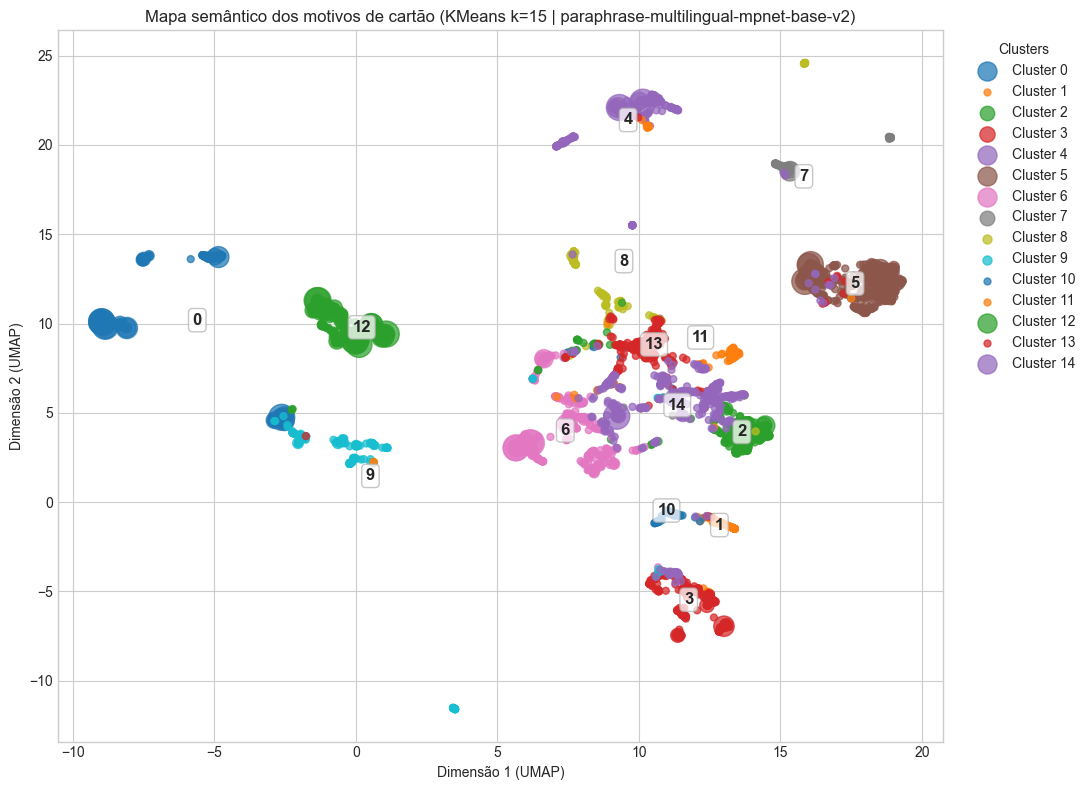

In [24]:
n_neighbors_viz = min(15, len(reason_counts) - 1)
reducer_2d = umap.UMAP(
    n_neighbors=n_neighbors_viz,
    min_dist=0.08,
    metric="cosine",
    random_state=RANDOM_STATE,
)
coords = reducer_2d.fit_transform(embeddings)

reason_counts["x"] = coords[:, 0]
reason_counts["y"] = coords[:, 1]

model_label = MODEL_NAME.split("/")[-1]

fig, ax = plt.subplots(figsize=(11, 8))
for cluster_id, group in reason_counts.groupby("cluster"):
    ax.scatter(
        group["x"], group["y"],
        s=np.clip(group["n_events"] * 6, 25, 350),
        alpha=0.72,
        label=f"Cluster {cluster_id}",
    )
for cluster_id, group in reason_counts.groupby("cluster"):
    centroid = group[["x", "y"]].mean()
    ax.text(
        centroid["x"], centroid["y"],
        str(cluster_id),
        fontsize=12, fontweight="bold", ha="center", va="center",
        bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "alpha": 0.75, "edgecolor": "0.7"},
    )
ax.set_title(f"Mapa semântico dos motivos de cartão (KMeans k={BEST_K} | {model_label})")
ax.set_xlabel("Dimensão 1 (UMAP)")
ax.set_ylabel("Dimensão 2 (UMAP)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Clusters")
plt.tight_layout()
plt.show()

In [25]:
fig_path = OUTPUT_DIR / "card_reason_semantic_map.png"

fig, ax = plt.subplots(figsize=(11, 8))
for cluster_id, group in reason_counts.groupby("cluster"):
    ax.scatter(
        group["x"], group["y"],
        s=np.clip(group["n_events"] * 6, 25, 350),
        alpha=0.72,
        label=f"Cluster {cluster_id}",
    )
for cluster_id, group in reason_counts.groupby("cluster"):
    centroid = group[["x", "y"]].mean()
    ax.text(
        centroid["x"], centroid["y"],
        str(cluster_id),
        fontsize=12, fontweight="bold", ha="center", va="center",
        bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "alpha": 0.75, "edgecolor": "0.7"},
    )
ax.set_title(f"Mapa semântico dos motivos de cartão (KMeans k={BEST_K} | {model_label})")
ax.set_xlabel("Dimensão 1 (UMAP)")
ax.set_ylabel("Dimensão 2 (UMAP)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Clusters")
plt.tight_layout()
fig.savefig(fig_path, dpi=180, bbox_inches="tight")
plt.close(fig)
fig_path

PosixPath('/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_semantic_map.png')

## **9. Leituras por Ano, Time e Árbitro**

In [26]:
cluster_by_year = pd.crosstab(
    reasons_clustered["year"],
    reasons_clustered["cluster"],
    normalize="index",
).round(3)

cluster_by_year

cluster,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
year,,,,,,,,,,,,,,,
2020,0.256,0.012,0.027,0.062,0.040,0.141,0.131,0.012,0.012,0.037,0.011,0.007,0.164,0.028,0.059
2021,0.221,0.009,0.048,0.061,0.057,0.164,0.102,0.014,0.022,0.032,0.008,0.014,0.157,0.032,0.058
2022,0.179,0.010,0.054,0.055,0.060,0.164,0.114,0.015,0.018,0.039,0.010,0.008,0.163,0.036,0.075
2023,0.139,0.007,0.063,0.061,0.063,0.157,0.135,0.024,0.016,0.028,0.006,0.014,0.180,0.030,0.077
2024,0.131,0.008,0.050,0.047,0.081,0.166,0.137,0.014,0.026,0.028,0.009,0.017,0.170,0.025,0.089
2025,0.112,0.011,0.063,0.043,0.054,0.133,0.164,0.023,0.023,0.025,0.010,0.016,0.234,0.022,0.067
2026,0.064,0.010,0.057,0.056,0.057,0.161,0.137,0.022,0.013,0.045,0.006,0.011,0.233,0.029,0.099


In [27]:
top_teams = reasons_clustered["team"].value_counts().head(12).index
cluster_by_team = pd.crosstab(
    reasons_clustered[reasons_clustered["team"].isin(top_teams)]["team"],
    reasons_clustered[reasons_clustered["team"].isin(top_teams)]["cluster"],
    normalize="index",
).round(3)

cluster_by_team

cluster,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
team,,,,,,,,,,,,,,,
Athletico Paranaense,0.165,0.013,0.062,0.055,0.079,0.130,0.134,0.024,0.018,0.062,0.011,0.007,0.145,0.018,0.077
Atlético Mineiro,0.179,0.006,0.039,0.051,0.068,0.143,0.141,0.017,0.023,0.028,0.011,0.004,0.167,0.034,0.090
Corinthians,0.203,0.019,0.038,0.056,0.046,0.155,0.115,0.013,0.027,0.025,0.004,0.010,0.171,0.038,0.079
Flamengo,0.160,0.013,0.060,0.067,0.035,0.132,0.119,0.022,0.019,0.041,0.009,0.015,0.214,0.024,0.071
Fluminense,0.163,0.005,0.044,0.060,0.071,0.171,0.116,0.015,0.020,0.024,0.002,0.018,0.191,0.022,0.080
Fortaleza Esporte Clube,0.190,0.018,0.045,0.059,0.066,0.161,0.133,0.018,0.016,0.016,0.007,0.014,0.152,0.032,0.075
Grêmio,0.131,0.011,0.044,0.031,0.077,0.170,0.177,0.018,0.004,0.024,0.018,0.018,0.177,0.022,0.077
Internacional,0.133,0.016,0.041,0.045,0.072,0.178,0.131,0.031,0.018,0.036,0.009,0.018,0.208,0.013,0.052
Palmeiras,0.167,0.006,0.051,0.047,0.049,0.174,0.133,0.024,0.021,0.011,0.011,0.011,0.167,0.039,0.088


In [28]:
top_referees = reasons_clustered["arbitro"].value_counts().head(12).index
cluster_by_referee = pd.crosstab(
    reasons_clustered[reasons_clustered["arbitro"].isin(top_referees)]["arbitro"],
    reasons_clustered[reasons_clustered["arbitro"].isin(top_referees)]["cluster"],
    normalize="index",
).round(3)

cluster_by_referee

cluster,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
arbitro,,,,,,,,,,,,,,,
Anderson Daronco,0.207,0.006,0.025,0.042,0.052,0.117,0.182,0.006,0.010,0.027,0.008,0.000,0.198,0.023,0.096
Braulio da Silva Machado,0.167,0.015,0.047,0.083,0.047,0.177,0.093,0.015,0.018,0.018,0.003,0.013,0.185,0.055,0.065
Bruno Arleu de Araujo,0.216,0.005,0.043,0.057,0.052,0.112,0.117,0.024,0.012,0.035,0.017,0.024,0.176,0.035,0.074
Felipe Fernandes de Lima,0.166,0.003,0.082,0.074,0.047,0.161,0.108,0.042,0.016,0.018,0.008,0.013,0.161,0.021,0.079
Flavio Rodrigues de Souza,0.179,0.015,0.038,0.045,0.051,0.157,0.147,0.023,0.034,0.028,0.008,0.009,0.149,0.023,0.094
Rafael Rodrigo Klein,0.104,0.013,0.037,0.078,0.078,0.175,0.125,0.023,0.023,0.029,0.003,0.013,0.188,0.042,0.068
Ramon Abatti Abel,0.132,0.005,0.034,0.080,0.056,0.145,0.154,0.011,0.018,0.043,0.009,0.011,0.178,0.024,0.100
Raphael Claus,0.213,0.012,0.054,0.058,0.044,0.099,0.143,0.015,0.006,0.027,0.008,0.004,0.209,0.029,0.079
Rodrigo Jose Pereira de Lima,0.093,0.013,0.062,0.052,0.047,0.181,0.168,0.008,0.021,0.023,0.010,0.010,0.231,0.016,0.065


## **10. Busca Semântica de Motivos Parecidos**

Consulta o espaço vetorial com qualquer texto em português. Exemplos:

- `semantic_search("reclamação contra arbitragem")`
- `semantic_search("entrada temerária na disputa de bola")`
- `semantic_search("retardar o reinício do jogo")`
- `semantic_search("conduta violenta")`

In [29]:
def embed_query(text: str) -> np.ndarray:
    return np.asarray(embedding_model.encode([text], normalize_embeddings=True))


def semantic_search(query: str, top_k: int = 10) -> pd.DataFrame:
    query_emb = embed_query(query)
    similarities = cosine_similarity(query_emb, embeddings).ravel()
    result = reason_counts.copy()
    result["similarity"] = similarities
    return result.sort_values("similarity", ascending=False)[[
        "cluster", "similarity", "n_events", "n_yellow", "n_red",
        "reason_category", "reason_detail", "reason",
    ]].head(top_k)


semantic_search("reclamação contra arbitragem", top_k=10)

,cluster,similarity,n_events,n_yellow,n_red,reason_category,reason_detail,reason
706,5,0.969793,2,2,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamação contra as decisoes da arbitragem,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamação contra as decisoes da arbitragem
2186,5,0.966743,1,1,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamacao contra arbitragem.,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamacao contra arbitragem.
708,5,0.965386,2,2,0,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,Por reclamação contra à arbitragem.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Por reclamação contra à arbitragem.
129,5,0.945632,10,10,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamação contra as decisões da arbitragem.,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamação contra as decisões da arbitragem.
2213,5,0.944300,1,1,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamação acintosa contra as decisões da arbitragem.,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamação acintosa contra as decisões da arbitragem.
2184,5,0.930012,1,1,0,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,Por reclamação discordando da decisão da arbitragem.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Por reclamação discordando da decisão da arbitragem.
2270,5,0.926986,1,1,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamar da arbitragem.,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamar da arbitragem.
2185,5,0.925635,1,1,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamação contra as decisões da arbitragem de maneira acintosa.,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamação contra as decisões da arbitragem de maneira acintosa.
2569,5,0.925269,1,1,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamar de uma decisão da arbitragem de forma acintosa.,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamar de uma decisão da arbitragem de forma acintosa.
2272,5,0.917813,1,1,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamar da marcação da arbitragem,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamar da marcação da arbitragem


## **11. Salvamento dos Artefatos**

In [30]:
reason_counts_path = OUTPUT_DIR / "card_reason_unique_clusters.csv"
reasons_clustered_path = OUTPUT_DIR / "card_reasons_long_with_clusters.csv"
cluster_summary_path = OUTPUT_DIR / "card_reason_cluster_summary.csv"
cluster_by_year_path = OUTPUT_DIR / "card_reason_clusters_by_year.csv"
cluster_by_team_path = OUTPUT_DIR / "card_reason_clusters_by_team_top12.csv"
cluster_by_referee_path = OUTPUT_DIR / "card_reason_clusters_by_referee_top12.csv"

reason_counts.to_csv(reason_counts_path, index=False)
reasons_clustered.to_csv(reasons_clustered_path, index=False)
cluster_summary.to_csv(cluster_summary_path, index=False)
cluster_by_year.to_csv(cluster_by_year_path)
cluster_by_team.to_csv(cluster_by_team_path)
cluster_by_referee.to_csv(cluster_by_referee_path)

print("Arquivos salvos:")
for path in [
    reason_counts_path, reasons_clustered_path, cluster_summary_path,
    cluster_by_year_path, cluster_by_team_path, cluster_by_referee_path, fig_path,
]:
    print(f"  {path}")

Arquivos salvos:
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_unique_clusters.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reasons_long_with_clusters.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_cluster_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_clusters_by_year.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_clusters_by_team_top12.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_clusters_by_referee_top12.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_semantic_map.png
